### Co-function, Fig. 4B

In [1]:
import numpy as np
import pandas as pd

gene_level_local_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_local_overlap_allpair.csv')
gene_level_global_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_global_overlap_allpair.csv')
local_metrics = np.sum(gene_level_local_metrics.set_index('gene')>2.5, axis=0)/gene_level_local_metrics.shape[0]
global_metrics = np.sum(gene_level_global_metrics.set_index('gene')>2.5, axis=0)/gene_level_global_metrics.shape[0]
local_metrics = local_metrics.reset_index()
global_metrics = global_metrics.reset_index()
prior_z_score = (gene_level_local_metrics.set_index('gene').mean(axis=1)+gene_level_global_metrics.set_index('gene').mean(axis=1))/2
prior_intrinsic_scores = (gene_level_local_metrics.set_index('gene')+gene_level_global_metrics.set_index('gene'))/2

In [2]:
import pandas as pd
gene_level_local_metrics = {}
gene_level_global_metrics = {}
analysis_targets = ['K562_GWPS','K562_Essential','RPE1_Essential','HepG2_Essential','Jurkat_Essential', 'RPE1_Southard']
for analysis_target in analysis_targets: 
    gene_level_local_metrics[analysis_target] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_local_overlap_allpair.csv').set_index('gene')
    gene_level_global_metrics[analysis_target] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_global_overlap_allpair.csv').set_index('gene')

import numpy as np

plot_df_local = []
plot_df_global = []
for analysis_target in analysis_targets: #,'RPE1_Southard']:
    local_metrics = np.sum(gene_level_local_metrics[analysis_target]>2.5, axis=0)/gene_level_local_metrics[analysis_target].shape[0]
    global_metrics = np.sum(gene_level_global_metrics[analysis_target]>2.5, axis=0)/gene_level_global_metrics[analysis_target].shape[0]
    plot_df_local.append(local_metrics)
    plot_df_global.append(global_metrics)

plot_df_local = pd.concat(plot_df_local, axis=1)
plot_df_local.columns=analysis_targets
plot_df_global = pd.concat(plot_df_global, axis=1)
plot_df_global.columns=analysis_targets

Text(25.84722222222222, 0.5, 'Co-function Agreement')

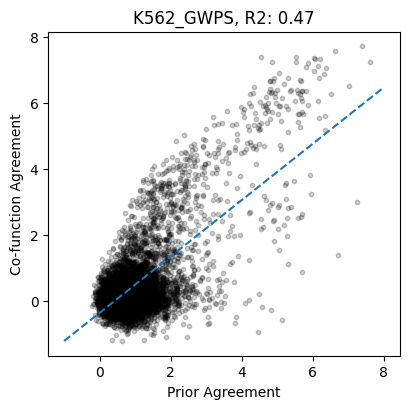

In [4]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr
plt.figure(figsize=(4,4))

prior_pert_z_scores = {}
perturb_seq_name = analysis_targets[0]
local_df = gene_level_local_metrics[perturb_seq_name].mean(axis=1)
global_df = gene_level_global_metrics[perturb_seq_name].mean(axis=1)
prior_pert_z_score = (global_df+local_df)/2
joint_idx = list(set(prior_z_score.index).intersection(set(prior_pert_z_score.index)))
tmp_prior_z = prior_z_score.loc[joint_idx]
tmp_prior_pert_z = prior_pert_z_score.loc[joint_idx]

prior_pert_z_scores[perturb_seq_name] = tmp_prior_pert_z

plt.scatter(tmp_prior_z, tmp_prior_pert_z, s=10, alpha=0.2, color='black')
#ax[i].set_title(f'Inter-prior agreement \n vs. ps-prior agreement \n {perturb_seq_name}, N={len(joint_idx)} \n Rs={spearmanr(tmp_prior_z, tmp_prior_pert_z).statistic:.2f}')    

X = tmp_prior_z.values
X = sm.add_constant(X)
y = tmp_prior_pert_z.values  
mod = sm.OLS(y, X)
resource = mod.fit()
plt.title(f'{perturb_seq_name}, R2: {resource.rsquared:.2f}')
x0 = -1
xt = 8
y0 = resource.params[0]+resource.params[1]*x0
yt = resource.params[0]+resource.params[1]*xt
plt.plot((x0, xt), (y0, yt), color='tab:blue', linestyle='--')
plt.tight_layout()
plt.xlabel('Prior Agreement')
plt.ylabel('Co-function Agreement')
#plt.savefig('../figure_out/Fig.4B_1.pdf')

In [5]:
import gseapy as gp

common_essential_genes = pd.read_csv("/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/CRISPRInferredCommonEssentials.csv")
# https://depmap.org/portal/data_page/?tab=allData,%20CRISPRInferredCommonEssentials.csv
common_essential_genes = common_essential_genes.map(lambda x: x.split(' ')[0])
common_essential_genes = common_essential_genes.values.flatten().tolist()
print(len(common_essential_genes))

tf_genes = pd.read_csv('/home/jhpark/page_reproducibility/04_genelevel_agreement/intermediate/infected_cells_per_guides_southard_rpe1_tf_crispra_effect_qc.csv')['guide'].tolist()
tf_genes.remove('off-target')
print(len(tf_genes))

1526
1832


In [6]:
library = gp.get_library(name='KEGG_2026', organism='Human')
signaling_genes = []

for key, val in library.items():
    if 'signaling' in key.lower():
        print(key)
        signaling_genes += val
signaling_genes = list(set(signaling_genes))
print(len(signaling_genes))

EPITHELIAL CELL SIGNALING IN HELICOBACTER PYLORI INFECTION
SIGNALING PATHWAYS REGULATING PLURIPOTENCY OF STEM CELLS
AGE-RAGE SIGNALING PATHWAY IN DIABETIC COMPLICATIONS
HIPPO SIGNALING PATHWAY - MULTIPLE SPECIES
C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY
ADRENERGIC SIGNALING IN CARDIOMYOCYTES
PHOSPHATIDYLINOSITOL SIGNALING SYSTEM
RIG-I-LIKE RECEPTOR SIGNALING PATHWAY
RETROGRADE ENDOCANNABINOID SIGNALING
TOLL-LIKE RECEPTOR SIGNALING PATHWAY
NOD-LIKE RECEPTOR SIGNALING PATHWAY
B CELL RECEPTOR SIGNALING PATHWAY
PHOSPHOLIPASE D SIGNALING PATHWAY
T CELL RECEPTOR SIGNALING PATHWAY
THYROID HORMONE SIGNALING PATHWAY
ADIPOCYTOKINE SIGNALING PATHWAY
FC EPSILON RI SIGNALING PATHWAY
NEUROTROPHIN SIGNALING PATHWAY
SPHINGOLIPID SIGNALING PATHWAY
NF-KAPPA B SIGNALING PATHWAY
NEUROACTIVE LIGAND SIGNALING
CHEMOKINE SIGNALING PATHWAY
PROLACTIN SIGNALING PATHWAY
ESTROGEN SIGNALING PATHWAY
GLUCAGON SIGNALING PATHWAY
HEDGEHOG SIGNALING PATHWAY
JAK-STAT SIGNALING PATHWAY
OXYTOCIN SIGNALING PATHWAY
PI3K-AKT SI

In [7]:
res_expressions = [
    pd.read_csv('/home/jhpark/page_reproducibility/04_genelevel_agreement/intermediate/ntc_exprs_mean_variance_replogle_k562_gwps.csv').set_index('gene'),
    pd.read_csv('/home/jhpark/page_reproducibility/04_genelevel_agreement/intermediate/ntc_exprs_mean_variance_replogle_k562_essential.csv').set_index('gene'),
    pd.read_csv('/home/jhpark/page_reproducibility/04_genelevel_agreement/intermediate/ntc_exprs_mean_variance_replogle_rpe1.csv').set_index('gene'),
    pd.read_csv('/home/jhpark/page_reproducibility/04_genelevel_agreement/intermediate/ntc_exprs_mean_variance_nadig_hepg2.csv').set_index('gene'),
    pd.read_csv('/home/jhpark/page_reproducibility/04_genelevel_agreement/intermediate/ntc_exprs_mean_variance_nadig_jurkat.csv').set_index('gene')
]

In [8]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
from statsmodels.stats.multitest import fdrcorrection
import warnings
warnings.filterwarnings('ignore')

r2_result = []
reg_result = []

for perturb_seq_idx in range(5):
    r2_result_cache = []
    prior_pert_z_scores = {}
    perturb_seq_name = analysis_targets[perturb_seq_idx]
    local_df = gene_level_local_metrics[perturb_seq_name].mean(axis=1)
    global_df = gene_level_global_metrics[perturb_seq_name].mean(axis=1)
    prior_pert_z_score = (global_df+local_df)/2
    joint_idx = list(set(prior_z_score.index).intersection(set(prior_pert_z_score.index)))
    tmp_prior_z = prior_z_score.loc[joint_idx]
    tmp_prior_pert_z = prior_pert_z_score.loc[joint_idx]

    is_common_essential=[]
    is_corum=[]
    is_signaling=[]
    is_tf=[]
    log_annotcounts = []
    mean_exp = []
    var_exp = []
    for gene in tmp_prior_pert_z.index.tolist():
        if gene in common_essential_genes:
            is_common_essential.append(1)
        else:
            is_common_essential.append(0)
        if gene in signaling_genes:
            is_signaling.append(1)
        else:
            is_signaling.append(0)
        if gene in tf_genes:
            is_tf.append(1)
        else:
            is_tf.append(0)
        if gene in res_expressions[perturb_seq_idx].index.tolist():
            mean_exp.append(float(res_expressions[perturb_seq_idx].loc[gene]['lognorm_mean']))
        else:
            mean_exp.append(np.nan)
        if gene in res_expressions[perturb_seq_idx].index.tolist():
            var_exp.append(float(res_expressions[perturb_seq_idx].loc[gene]['lognorm_var']))
        else:
            var_exp.append(np.nan)

    df_lm = pd.DataFrame([tmp_prior_z.values.tolist(), is_common_essential, is_signaling, is_tf, mean_exp, var_exp], columns=tmp_prior_z.index.tolist()).T
    df_lm.columns = ['intrinsic', 'essential', 'signaling', 'tf', 'mean_exp', 'var_exp']


    if perturb_seq_idx > 0:
        n_covs = 4
    else:
        n_covs = 5

    if perturb_seq_idx > 0:
        df_lm = df_lm.drop(['essential'], axis=1)

    df_lm_fill = df_lm.fillna(value = df_lm.mean(axis=0))

    cmap = cm.get_cmap('Blues') 
    norm = mcolors.Normalize(vmin=0, vmax=1)
    s_mappable = cm.ScalarMappable(norm=norm, cmap=cmap)
    bar_colors = [s_mappable.to_rgba(0.5+i/16) for i in range(n_covs)]

    X = df_lm_fill.values
    
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    print('VIF:', [variance_inflation_factor(X, i) for i in range(X.shape[1])])

    X = sm.add_constant(X)
    
    y = tmp_prior_pert_z.values
    
    mod = sm.OLS(y, X[:, [0, 1]])
    resource = mod.fit()
    r2_result_cache.append(resource.rsquared)

    mod = sm.OLS(y, X)
    resource = mod.fit()
    coefs = resource.params[1:]
    fdrs = fdrcorrection(resource.pvalues, alpha=0.05, method='indep', is_sorted=False)[1][1:]
    r2_result_cache.append(resource.rsquared)
    r2_result.append(r2_result_cache)

    reg_result_cache = np.sign(coefs)*-np.log10(fdrs+1e-10)
    if perturb_seq_idx > 0:
        reg_result_cache = [float(reg_result_cache[0]), 0]+reg_result_cache[1:].tolist()
    else:
        reg_result_cache = reg_result_cache.tolist()
    reg_result.append(reg_result_cache)

VIF: [np.float64(2.72072805048679), np.float64(1.478830861880136), np.float64(1.149399497125891), np.float64(1.144580189808393), np.float64(2.8039320890657202), np.float64(3.138901922720497)]
VIF: [np.float64(3.1987868436457236), np.float64(1.1211270187702265), np.float64(1.0912441211690476), np.float64(2.485651460836754), np.float64(2.756249273160356)]
VIF: [np.float64(2.7629648813681933), np.float64(1.120458542422876), np.float64(1.0949676146062293), np.float64(2.2145008889953712), np.float64(2.5673625172225574)]
VIF: [np.float64(2.7245873878480187), np.float64(1.1308246389988728), np.float64(1.086992681209392), np.float64(2.367455472201773), np.float64(2.593807123023622)]
VIF: [np.float64(2.9186651933287044), np.float64(1.1192068158849315), np.float64(1.1029318276120703), np.float64(2.6070672451099512), np.float64(2.8663907845983427)]


Text(0, 0.5, 'Coefficient of Determination($R^2$)')

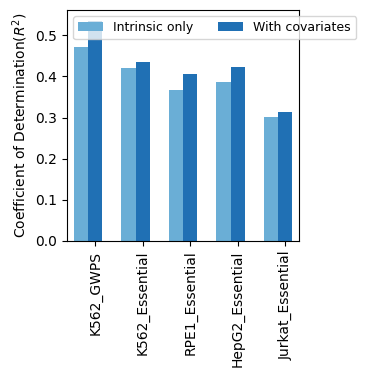

In [9]:
plot_df = pd.DataFrame(r2_result, index=analysis_targets[:5], columns=['Intrinsic only', 'With covariates']).T
width=0.3
multiplier=0

fig, ax = plt.subplots(1, 1, figsize=(3, 3))
x = np.arange(5)

cmap = cm.get_cmap('Blues') 
norm = mcolors.Normalize(vmin=0, vmax=1)
s_mappable = cm.ScalarMappable(norm=norm, cmap=cmap)
bar_colors = [s_mappable.to_rgba(0.5+i/4) for i in range(2)]

for attribute, measurement in plot_df.T.to_dict().items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement.values(), width, label=attribute, color=bar_colors[multiplier])
    #ax.bar_label(rects, padding=3)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xticks(x + width, plot_df.columns)
ax.legend(loc='upper left', ncols=5, fontsize=9)
plt.xlim(-0.3, 4.6)
plt.xticks(label=analysis_targets[:5], rotation=90)
plt.ylabel('Coefficient of Determination($R^2$)')
#plt.savefig('../figure_out/Fig.4B_2.pdf')

In [10]:
plot_df = pd.DataFrame(r2_result, index=analysis_targets[:5], columns=['Intrinsic only', 'With covariates']).T
plot_df.T['With covariates']-plot_df.T['Intrinsic only']

K562_GWPS           0.063976
K562_Essential      0.015819
RPE1_Essential      0.039337
HepG2_Essential     0.037936
Jurkat_Essential    0.011083
dtype: float64

### Fig. 4D

Text(0, 0.5, 'Signed -$log(P_{adj})$')

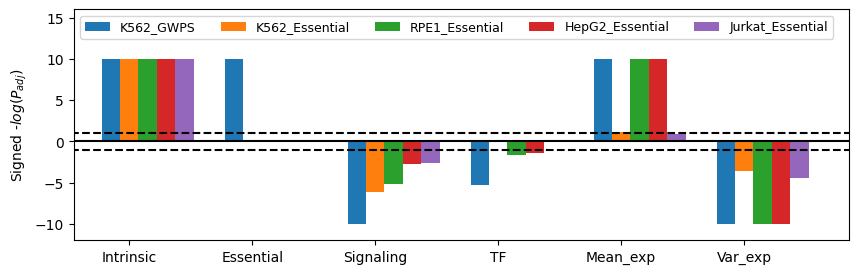

In [11]:
plot_df = pd.DataFrame(reg_result, index=analysis_targets[:5], columns=['Intrinsic', 'Essential', 'Signaling', 'TF', 'Mean_exp', 'Var_exp'])
width=0.15
multiplier=0

fig, ax = plt.subplots(1, 1, figsize=(10, 3))
x = np.arange(6)

#cmap = cm.get_cmap('Blues') 
#norm = mcolors.Normalize(vmin=0, vmax=1)
#s_mappable = cm.ScalarMappable(norm=norm, cmap=cmap)
#bar_colors = [s_mappable.to_rgba(0.5+i/10) for i in range(5)][::-1]

for attribute, measurement in plot_df.T.to_dict().items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement.values(), width, label=attribute)#, color=bar_colors[multiplier])
    #ax.bar_label(rects, padding=3)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xticks(x + width, plot_df.columns)
ax.legend(loc='upper left', ncols=5, fontsize=9)
plt.hlines(xmin=-0.5, xmax=8, y=-np.log10(0.10), linestyle='--', color='black')
plt.hlines(xmin=-0.5, xmax=8, y=+np.log10(0.10), linestyle='--', color='black')
plt.hlines(xmin=-0.5, xmax=8, y=0, linestyle='-', color='black')
plt.xlim(-0.3, 6)
plt.ylim(-12, 16)
plt.ylabel('Signed -$log(P_{adj})$')
#plt.savefig('../figure_out/Fig.4D.pdf')

### Co-regulation, Fig. 4C

In [12]:
import pandas as pd
gene_level_local_metrics = {}
gene_level_global_metrics = {}
analysis_targets = ['K562_GWPS','K562_Essential','RPE1_Essential','HepG2_Essential','Jurkat_Essential','RPE1_Southard']
for perturb_seq_name in analysis_targets: 
    gene_level_local_metrics[perturb_seq_name] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{perturb_seq_name}_mrnaspace_gene_local_overlap_allpair.csv').set_index('gene')
    gene_level_global_metrics[perturb_seq_name] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{perturb_seq_name}_mrnaspace_gene_global_overlap_allpair.csv').set_index('gene')

import numpy as np

plot_df_local = []
plot_df_global = []
for analysis_target in analysis_targets: #,'RPE1_Southard']:
    local_metrics = np.sum(gene_level_local_metrics[analysis_target]>2.5, axis=0)/gene_level_local_metrics[analysis_target].shape[0]
    global_metrics = np.sum(gene_level_global_metrics[analysis_target]>2.5, axis=0)/gene_level_global_metrics[analysis_target].shape[0]
    local_metrics = local_metrics
    global_metrics = global_metrics
    plot_df_local.append(local_metrics)
    plot_df_global.append(global_metrics)

plot_df_local = pd.concat(plot_df_local, axis=1)
plot_df_local.columns=analysis_targets
plot_df_global = pd.concat(plot_df_global, axis=1)
plot_df_global.columns=analysis_targets

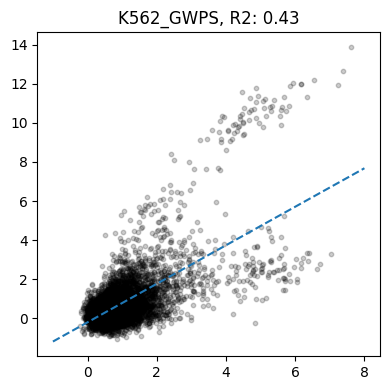

In [16]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr
plt.figure(figsize=(4,4))

prior_pert_z_scores = {}
perturb_seq_name = analysis_targets[0]
local_df = gene_level_local_metrics[perturb_seq_name].mean(axis=1)
global_df = gene_level_global_metrics[perturb_seq_name].mean(axis=1)
prior_pert_z_score = (global_df+local_df)/2
joint_idx = list(set(prior_z_score.index).intersection(set(prior_pert_z_score.index)))
tmp_prior_z = prior_z_score.loc[joint_idx]
tmp_prior_pert_z = prior_pert_z_score.loc[joint_idx]

prior_pert_z_scores[perturb_seq_name] = tmp_prior_pert_z

plt.scatter(tmp_prior_z, tmp_prior_pert_z, s=10, alpha=0.2, color='black')
#ax[i].set_title(f'Inter-prior agreement \n vs. ps-prior agreement \n {perturb_seq_name}, N={len(joint_idx)} \n Rs={spearmanr(tmp_prior_z, tmp_prior_pert_z).statistic:.2f}')    

X = tmp_prior_z.values
X = sm.add_constant(X)
y = tmp_prior_pert_z.values  
mod = sm.OLS(y, X)
resource = mod.fit()
plt.title(f'{perturb_seq_name}, R2: {resource.rsquared:.2f}')
x0 = -1
xt = 8
y0 = resource.params[0]+resource.params[1]*x0
yt = resource.params[0]+resource.params[1]*xt
plt.plot((x0, xt), (y0, yt), color='tab:blue', linestyle='--')
plt.tight_layout()
#plt.savefig('../figure_out/Fig.4C_1.pdf')

In [13]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
from statsmodels.stats.multitest import fdrcorrection
import warnings
warnings.filterwarnings('ignore')

r2_result = []
reg_result = []

for perturb_seq_idx in range(5):
    r2_result_cache = []
    prior_pert_z_scores = {}
    perturb_seq_name = analysis_targets[perturb_seq_idx]
    local_df = gene_level_local_metrics[perturb_seq_name].mean(axis=1)
    global_df = gene_level_global_metrics[perturb_seq_name].mean(axis=1)
    prior_pert_z_score = (global_df+local_df)/2
    joint_idx = list(set(prior_z_score.index).intersection(set(prior_pert_z_score.index)))
    tmp_prior_z = prior_z_score.loc[joint_idx]
    tmp_prior_pert_z = prior_pert_z_score.loc[joint_idx]

    is_common_essential=[]
    is_corum=[]
    is_signaling=[]
    is_tf=[]
    log_annotcounts = []
    mean_exp = []
    var_exp = []
    for gene in tmp_prior_pert_z.index.tolist():
        if gene in common_essential_genes:
            is_common_essential.append(1)
        else:
            is_common_essential.append(0)
        if gene in signaling_genes:
            is_signaling.append(1)
        else:
            is_signaling.append(0)
        if gene in tf_genes:
            is_tf.append(1)
        else:
            is_tf.append(0)
        if gene in res_expressions[perturb_seq_idx].index.tolist():
            mean_exp.append(float(res_expressions[perturb_seq_idx].loc[gene]['lognorm_mean']))
        else:
            mean_exp.append(np.nan)
        if gene in res_expressions[perturb_seq_idx].index.tolist():
            var_exp.append(float(res_expressions[perturb_seq_idx].loc[gene]['lognorm_var']))
        else:
            var_exp.append(np.nan)

    df_lm = pd.DataFrame([tmp_prior_z.values.tolist(), is_common_essential, is_signaling, is_tf, mean_exp, var_exp], columns=tmp_prior_z.index.tolist()).T
    df_lm.columns = ['intrinsic', 'essential', 'signaling', 'tf', 'mean_exp', 'var_exp']


    if perturb_seq_idx > 0:
        n_covs = 4
    else:
        n_covs = 5

    if perturb_seq_idx > 0:
        df_lm = df_lm.drop(['essential'], axis=1)

    df_lm_fill = df_lm.fillna(value = df_lm.mean(axis=0))

    cmap = cm.get_cmap('Blues') 
    norm = mcolors.Normalize(vmin=0, vmax=1)
    s_mappable = cm.ScalarMappable(norm=norm, cmap=cmap)
    bar_colors = [s_mappable.to_rgba(0.5+i/16) for i in range(n_covs)]

    X = df_lm_fill.values
    
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    print('VIF:', [variance_inflation_factor(X, i) for i in range(X.shape[1])])

    X = sm.add_constant(X)
    
    y = tmp_prior_pert_z.values
    
    mod = sm.OLS(y, X[:, [0, 1]])
    resource = mod.fit()
    r2_result_cache.append(resource.rsquared)

    mod = sm.OLS(y, X)
    resource = mod.fit()
    coefs = resource.params[1:]
    fdrs = fdrcorrection(resource.pvalues, alpha=0.05, method='indep', is_sorted=False)[1][1:]
    r2_result_cache.append(resource.rsquared)
    r2_result.append(r2_result_cache)

    reg_result_cache = np.sign(coefs)*-np.log10(fdrs+1e-10)
    if perturb_seq_idx > 0:
        reg_result_cache = [float(reg_result_cache[0]), 0]+reg_result_cache[1:].tolist()
    else:
        reg_result_cache = reg_result_cache.tolist()
    reg_result.append(reg_result_cache)

VIF: [np.float64(2.6691108888783655), np.float64(1.544938389367394), np.float64(1.14877332503035), np.float64(1.0781898492390891), np.float64(2.611694801699378), np.float64(2.877418004375158)]
VIF: [np.float64(2.448169897919949), np.float64(1.1342316676138604), np.float64(1.0804749294351326), np.float64(2.576744314228414), np.float64(2.850373104916343)]
VIF: [np.float64(2.166244365076151), np.float64(1.1548081656863618), np.float64(1.0693727486101052), np.float64(2.4048667304625377), np.float64(2.6879956603072266)]
VIF: [np.float64(2.11753454312045), np.float64(1.1500784072311165), np.float64(1.0680306140750802), np.float64(2.610967853670431), np.float64(2.7355694769272434)]
VIF: [np.float64(2.366073064052181), np.float64(1.1375438982328745), np.float64(1.0854966069765752), np.float64(2.802266275066572), np.float64(3.108176150359411)]


Text(0, 0.5, 'Coefficient of Determination($R^2$)')

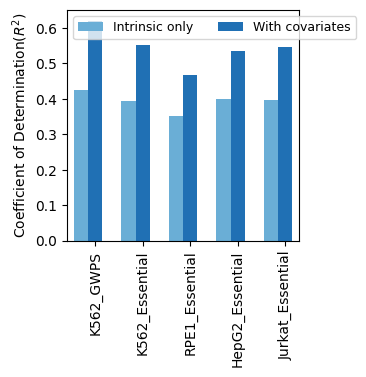

In [17]:
plot_df = pd.DataFrame(r2_result, index=analysis_targets[:5], columns=['Intrinsic only', 'With covariates']).T
width=0.3
multiplier=0

fig, ax = plt.subplots(1, 1, figsize=(3, 3))
x = np.arange(5)

cmap = cm.get_cmap('Blues') 
norm = mcolors.Normalize(vmin=0, vmax=1)
s_mappable = cm.ScalarMappable(norm=norm, cmap=cmap)
bar_colors = [s_mappable.to_rgba(0.5+i/4) for i in range(2)]

for attribute, measurement in plot_df.T.to_dict().items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement.values(), width, label=attribute, color=bar_colors[multiplier])
    #ax.bar_label(rects, padding=3)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xticks(x + width, plot_df.columns)
ax.legend(loc='upper left', ncols=5, fontsize=9)
plt.xlim(-0.3, 4.6)
plt.xticks(label=analysis_targets[:5], rotation=90)
plt.ylabel('Coefficient of Determination($R^2$)')
#plt.savefig('../figure_out/Final_Fig.4C_2.pdf')

In [18]:
plot_df = pd.DataFrame(r2_result, index=analysis_targets[:5], columns=['Intrinsic only', 'With covariates']).T
plot_df.T['With covariates']-plot_df.T['Intrinsic only']

K562_GWPS           0.193669
K562_Essential      0.159026
RPE1_Essential      0.114819
HepG2_Essential     0.137062
Jurkat_Essential    0.148528
dtype: float64

### Fig. 4E

Text(0, 0.5, 'Signed -$log(P_{adj})$')

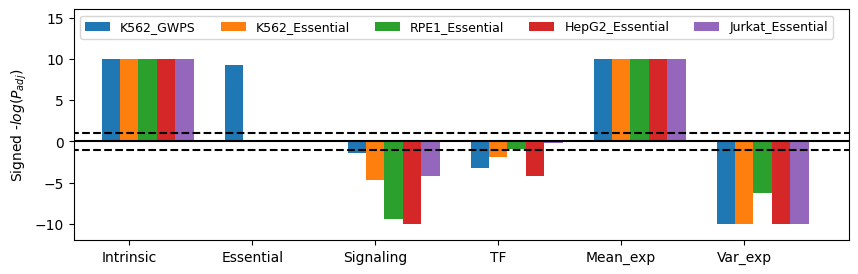

In [19]:
plot_df = pd.DataFrame(reg_result, index=analysis_targets[:5], columns=['Intrinsic', 'Essential', 'Signaling', 'TF', 'Mean_exp', 'Var_exp'])
width=0.15
multiplier=0

fig, ax = plt.subplots(1, 1, figsize=(10, 3))
x = np.arange(6)

#cmap = cm.get_cmap('Blues') 
#norm = mcolors.Normalize(vmin=0, vmax=1)
#s_mappable = cm.ScalarMappable(norm=norm, cmap=cmap)
#bar_colors = [s_mappable.to_rgba(0.5+i/10) for i in range(5)][::-1]

for attribute, measurement in plot_df.T.to_dict().items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement.values(), width, label=attribute)#, color=bar_colors[multiplier])
    #ax.bar_label(rects, padding=3)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xticks(x + width, plot_df.columns)
ax.legend(loc='upper left', ncols=5, fontsize=9)
plt.hlines(xmin=-0.5, xmax=8, y=-np.log10(0.10), linestyle='--', color='black')
plt.hlines(xmin=-0.5, xmax=8, y=+np.log10(0.10), linestyle='--', color='black')
plt.hlines(xmin=-0.5, xmax=8, y=0, linestyle='-', color='black')
plt.xlim(-0.3, 6)
plt.ylim(-12, 16)
plt.ylabel('Signed -$log(P_{adj})$')
#plt.savefig('../figure_out/Fig.4E.pdf')